# UD1 · Clase · Estadística descriptiva y funciones de agregación en Big Data

**MP5074 Sistemas de Big Data**

Versión para una **sesión de 2 horas**. Acompaña al [manual de estadística de la web](https://rafafl-wirtz.github.io/mp5074-sistemas-big-data/ud1/manuales/estadistica/manual_estadistica/)
con **sus mismos ejemplos**. Al final, en **Para ampliar**, hay material extra que no está en el manual.


Las cajas **Qué observar** marcan lo que hay que hacer notar en cada celda, y las **Pregunta para la
clase** se lanzan en voz alta *antes* de ejecutar la celda siguiente.

## 0. Preparación

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 2)
plt.rcParams["figure.figsize"] = (8, 3)

print("pandas", pd.__version__)

pandas 3.0.5


## 1. ¿Por qué estadística en un sistema de Big Data? · 5 min

Un humano no puede leer mil millones de filas. Un sistema de Big Data sí, pero lo que entrega a las
personas (un informe, un *dashboard*, una alerta) son siempre **resúmenes**.

- **Agregación**: operación que toma un conjunto de valores y devuelve un único valor que los resume.
- **Estadística descriptiva**: describe y resume un conjunto de datos, sin sacar conclusiones sobre una población mayor.

Para verlo, generamos un millón de pedidos ficticios: nadie puede mirarlos, pero cinco números los resumen.

In [2]:
rng = np.random.default_rng(42)
importes = pd.Series(rng.lognormal(mean=5, sigma=1, size=1_000_000), name="importe")

print(f"{len(importes):,} importes")
importes.head()

1,000,000 importes


0    201.28
1     52.46
2    314.33
3    380.15
4     21.09
Name: importe, dtype: float64

In [3]:
importes.agg(["count", "sum", "mean", "median", "max"]).map("{:,.2f}".format)

count       1,000,000.00
sum       244,893,267.52
mean              244.89
median            148.30
max            22,186.41
Name: importe, dtype: str

> **Qué observar.** Un millón de filas resumidas en cinco números. Fíjate ya en que la **media** (≈ 245) y la **mediana**
(≈ 148) son muy distintas: es la primera pista de todo lo que veremos hoy.

## 2. Medidas de tendencia central · 20 min

Responden a *«¿cuál es el valor típico?»*.

### 2.1 Media, 2.2 mediana y 2.3 moda: el ejemplo de los sueldos

Sueldos mensuales de una pequeña empresa de 7 personas:

In [4]:
sueldos = pd.Series([1500, 1600, 1600, 1800, 2000, 2200, 25000], name="sueldo")
sueldos

0     1500
1     1600
2     1600
3     1800
4     2000
5     2200
6    25000
Name: sueldo, dtype: int64

> **Pregunta para la clase.** Antes de calcular nada: ¿cuál diríais que es el sueldo «típico» de esta empresa?

**Media** $\bar{x} = \dfrac{\sum x_i}{n}$: la suma entre el número de datos. La calculamos «a mano» y con pandas:

In [5]:
print("A mano:", sueldos.sum(), "/", len(sueldos), "=", sueldos.sum() / len(sueldos))
print("pandas:", sueldos.mean())

A mano: 35700 / 7 = 5100.0
pandas: 5100.0


**Mediana**: el valor central de los datos **ordenados**. Con 7 datos, el 4.º:

In [6]:
ordenados = sueldos.sort_values().reset_index(drop=True)
print(ordenados.tolist())
print("Posición central (4.º):", ordenados[3])
print("pandas:", sueldos.median())

[1500, 1600, 1600, 1800, 2000, 2200, 25000]
Posición central (4.º): 1800
pandas: 1800.0


**Moda**: el valor que más se repite. `mode()` devuelve **siempre una serie**, porque puede haber varias modas.

In [7]:
print(sueldos.value_counts().head(3))
sueldos.mode()

sueldo
1600    2
1500    1
1800    1
Name: count, dtype: int64


0    1600
Name: sueldo, dtype: int64

Las tres juntas, como en la tabla del manual, y en un gráfico:

media      5100.0
mediana    1800.0
moda       1600.0
dtype: float64


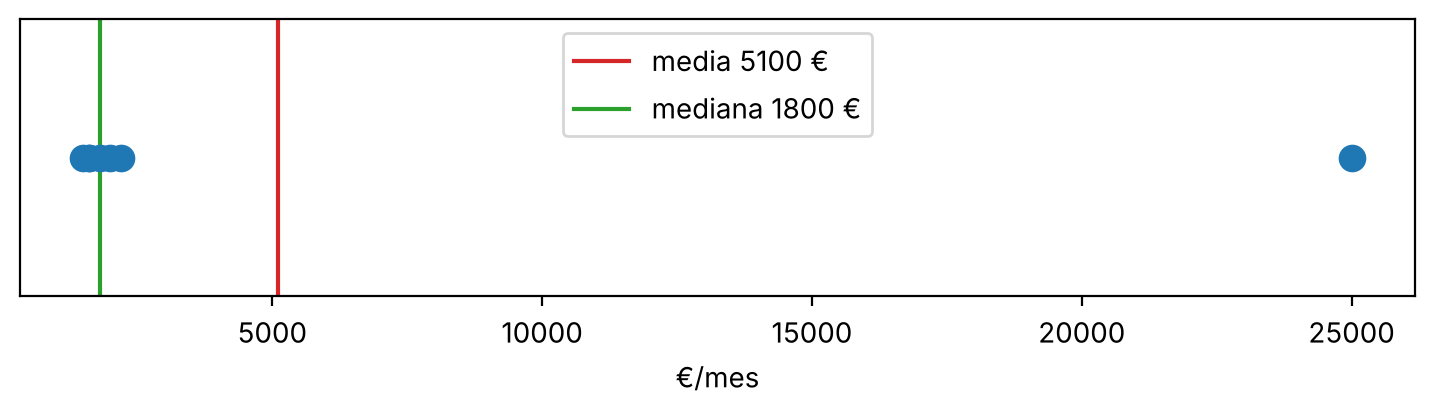

In [8]:
resumen = pd.Series({"media": sueldos.mean(), "mediana": sueldos.median(), "moda": sueldos.mode()[0]})
print(resumen)

fig, ax = plt.subplots(figsize=(9, 1.8))
ax.scatter(sueldos, [0] * len(sueldos), s=80, zorder=3)
ax.axvline(sueldos.mean(), color="tab:red", label=f"media {sueldos.mean():.0f} €")
ax.axvline(sueldos.median(), color="tab:green", label=f"mediana {sueldos.median():.0f} €")
ax.set_yticks([]); ax.set_xlabel("€/mes"); ax.legend(loc="upper center")
plt.show()

> **Qué observar.** **Solo una persona cobra más de 2200 €** y, sin embargo, la media dice 5100 €. Un único valor
extremo arrastra la media; la mediana ni se entera. Cuando media y mediana se separan mucho → distribución
**asimétrica** o hay **atípicos**. Comparar ambas es lo primero que hay que hacer con un dataset.

### Moda con datos categóricos

La moda es la única de las tres que funciona con **categorías**: «método de pago más frecuente» tiene
sentido; «método de pago medio», no.

In [9]:
pagos = pd.Series(["Tarjeta", "Bizum", "Tarjeta", "PayPal",
                   "Bizum", "Tarjeta", "Bizum", "Transferencia"])
print(pagos.value_counts())
pagos.mode()

Tarjeta          3
Bizum            3
PayPal           1
Transferencia    1
Name: count, dtype: int64


0      Bizum
1    Tarjeta
dtype: str

In [10]:
try:
    pagos.mean()
except TypeError as e:
    print("No se puede calcular la media de un texto:", type(e).__name__)

No se puede calcular la media de un texto: TypeError


> **Qué observar.** Tarjeta y Bizum empatan con 3: la distribución es **bimodal**, y por eso `mode()` devuelve dos valores.

### 2.5 Media ponderada

$\bar{x}_w = \dfrac{\sum w_i x_i}{\sum w_i}$. Una tienda vende 100 unidades de un producto de 10 € y
1 unidad de uno de 100 €.

> **Pregunta para la clase.** ¿Cuánto paga de media un cliente por cada unidad que compra?

In [11]:
ventas_tienda = pd.DataFrame({"precio": [10, 100], "unidades": [100, 1]})

media_simple = ventas_tienda["precio"].mean()
media_ponderada = (ventas_tienda["precio"] * ventas_tienda["unidades"]).sum() / ventas_tienda["unidades"].sum()
# equivalente con NumPy:
np_ponderada = np.average(ventas_tienda["precio"], weights=ventas_tienda["unidades"])

print(f"Media simple:    {media_simple:.2f} €")
print(f"Media ponderada: {media_ponderada:.2f} €  (NumPy: {np_ponderada:.2f})")

Media simple:    55.00 €
Media ponderada: 10.89 €  (NumPy: 10.89)


> **Qué observar.** 55 € responde a «precio medio del catálogo»; 10,89 € responde a «precio medio por unidad vendida».
Son preguntas distintas. En Big Data el error típico es hacer una media simple de valores que ya eran
medias: lo veremos en el apartado 5.

## 3. Medidas de dispersión y de posición · 30 min

Dos conjuntos con **la misma media** pueden ser muy distintos:

Media A: 50.0   Media B: 50.0


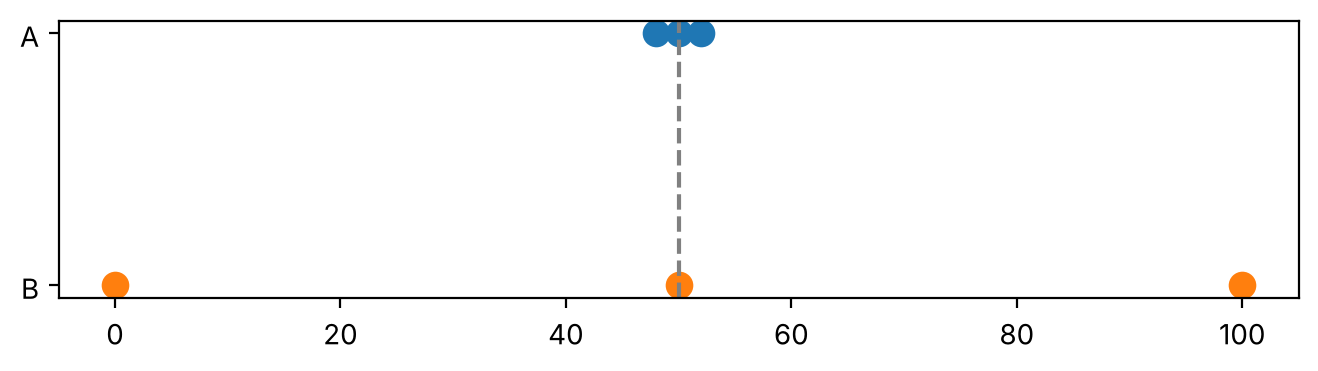

In [12]:
A = pd.Series([48, 50, 52])
B = pd.Series([0, 50, 100])
print("Media A:", A.mean(), "  Media B:", B.mean())

fig, ax = plt.subplots(figsize=(8, 1.8))
ax.scatter(A, [1] * 3, s=80, label="A"); ax.scatter(B, [0] * 3, s=80, label="B")
ax.axvline(50, color="grey", ls="--"); ax.set_yticks([0, 1], ["B", "A"]); plt.show()

### 3.2 Varianza y desviación típica

**¿Para qué sirven?** Para medir **cuánto se alejan los datos de la media**, es decir, si la media es un
buen resumen o no. Si la desviación típica es pequeña, casi todos los datos están cerca de la media y
podemos fiarnos de ella; si es grande, los datos están muy repartidos y la media por sí sola dice poco.

> **Pregunta para la clase.** Dos repartidores tardan de media 30 minutos. El primero tarda siempre entre 28 y 32; el segundo,
a veces 10 y a veces 50. ¿De cuál os fiaríais para prometer una hora de entrega? ¿Qué número mide esa diferencia?

**Cómo se calcula, paso a paso:** 1) la media; 2) cuánto se aleja cada dato de ella (la **desviación**);
3) se elevan al cuadrado, para que las negativas no anulen a las positivas y las grandes pesen más;
4) la «media» de esos cuadrados es la **varianza**; 5) como está en unidades al cuadrado (minutos², €²),
se hace la raíz: la **desviación típica**, otra vez en minutos o euros.

$s^2 = \dfrac{\sum (x_i - \bar{x})^2}{n - 1}$, y $s = \sqrt{s^2}$ (en las **mismas unidades** que los datos).
Reproducimos la tabla del manual paso a paso:

In [13]:
def varianza_paso_a_paso(x):
    tabla = pd.DataFrame({"dato": x})
    tabla["desviacion"] = tabla["dato"] - x.mean()
    tabla["cuadrado"] = tabla["desviacion"] ** 2
    suma = tabla["cuadrado"].sum()
    var = suma / (len(x) - 1)
    print(tabla.to_string(index=False))
    print(f"suma = {suma:.0f}   s² = {suma:.0f} / {len(x) - 1} = {var:.0f}   s = {var ** 0.5:.0f}\n")

varianza_paso_a_paso(A)
varianza_paso_a_paso(B)

 dato  desviacion  cuadrado
   48        -2.0       4.0
   50         0.0       0.0
   52         2.0       4.0
suma = 8   s² = 8 / 2 = 4   s = 2

 dato  desviacion  cuadrado
    0       -50.0    2500.0
   50         0.0       0.0
  100        50.0    2500.0
suma = 5000   s² = 5000 / 2 = 2500   s = 50



In [14]:
print("pandas:", A.var(), A.std(), "  |  ", B.var(), B.std())

pandas: 4.0 2.0   |   2500.0 50.0


> **Qué observar.** Misma media, pero los datos de B están 25 veces más lejos de ella (s = 50 frente a s = 2).
**Cómo se lee:** «los datos se alejan de la media, más o menos, *s* unidades»: en A, unos 2 puntos arriba
o abajo de 50 (homogéneo); en B, unos 50 (disperso). En Big Data se usa para **detectar anomalías**
(un sensor que se aleja mucho de su variación habitual), **control de calidad** y **normalizar** variables
en Machine Learning.

### 3.4 Cuartiles, percentiles y rango intercuartílico

Minutos que tardan en prepararse 9 pedidos:

In [15]:
prep = pd.Series([12, 15, 15, 18, 20, 22, 25, 30, 95], name="minutos")
q1, q2, q3 = prep.quantile([0.25, 0.50, 0.75])
iqr = q3 - q1
print(f"Q1 = {q1}  Q2 (mediana) = {q2}  Q3 = {q3}  IQR = {iqr}")

Q1 = 15.0  Q2 (mediana) = 20.0  Q3 = 25.0  IQR = 10.0


In [16]:
prep.describe()

count     9.00
mean     28.00
std      25.73
min      12.00
25%      15.00
50%      20.00
75%      25.00
max      95.00
Name: minutos, dtype: float64

> **Qué observar.** `describe()` da de un vistazo tendencia central, dispersión y cuartiles. Compara: la **media** (28) y la
**desviación típica** se disparan por el pedido de 95 min; **Q1, mediana y Q3 no se mueven**.

Lo comprobamos quitando el pedido de 95 minutos:

In [17]:
comparacion = pd.DataFrame({
    "con 95 min": prep.describe(),
    "sin 95 min": prep[prep < 95].describe(),
})
comparacion.loc[["mean", "std", "25%", "50%", "75%", "max"]]

,con 95 min,sin 95 min
mean,28.00,19.62
std,25.73,5.93
25%,15.00,15.00
50%,20.00,19.00
75%,25.00,22.75
max,95.00,30.00


### 3.5 Percentiles en la práctica: tiempos de respuesta

En monitorización no se usa la media del tiempo de respuesta, sino el **p95** y el **p99**.

In [18]:
tiempos = pd.Series([110, 120, 125, 130, 140, 150, 160, 180, 900, 2500], name="ms")
print("Media:", tiempos.mean())
tiempos.quantile([0.5, 0.90, 0.95])

Media: 451.5


0.50     145.0
0.90    1060.0
0.95    1780.0
Name: ms, dtype: float64

> **Pregunta para la clase.** La media es 451,5 ms. ¿Cuántas peticiones han tardado algo parecido a 451,5 ms?

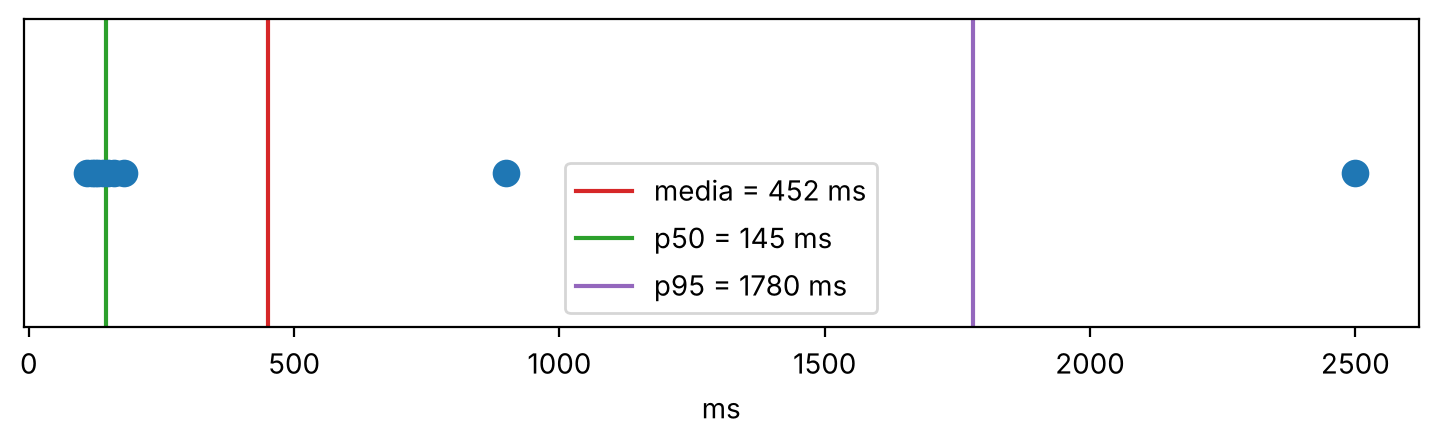

In [19]:
fig, ax = plt.subplots(figsize=(9, 2))
ax.scatter(tiempos, [0] * len(tiempos), s=80, zorder=3)
for valor, nombre, color in [(tiempos.mean(), "media", "tab:red"),
                             (tiempos.median(), "p50", "tab:green"),
                             (tiempos.quantile(0.95), "p95", "tab:purple")]:
    ax.axvline(valor, color=color, label=f"{nombre} = {valor:.0f} ms")
ax.set_yticks([]); ax.set_xlabel("ms"); ax.legend(); plt.show()

> **Qué observar.** **Ninguna**: 8 tardan mucho menos y 2 mucho más. La media describe a un usuario que no existe;
la mediana describe la petición normal y el p95 describe a los usuarios que lo pasan mal. Por eso los
SLA se escriben en percentiles. (Con 10 datos, pandas interpola p90 y p95 entre el 9.º y el 10.º valor.)

### 3.6 Valores atípicos: la regla del IQR

Atípico = fuera de $[\,Q1 - 1{,}5 \cdot IQR,\ Q3 + 1{,}5 \cdot IQR\,]$.

In [20]:
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
print(f"Intervalo normal: [{lim_inf}, {lim_sup}]")

atipicos = prep[(prep < lim_inf) | (prep > lim_sup)]
atipicos

Intervalo normal: [0.0, 40.0]


8    95
Name: minutos, dtype: int64

El **diagrama de caja** (*boxplot*) dibuja exactamente esta regla:

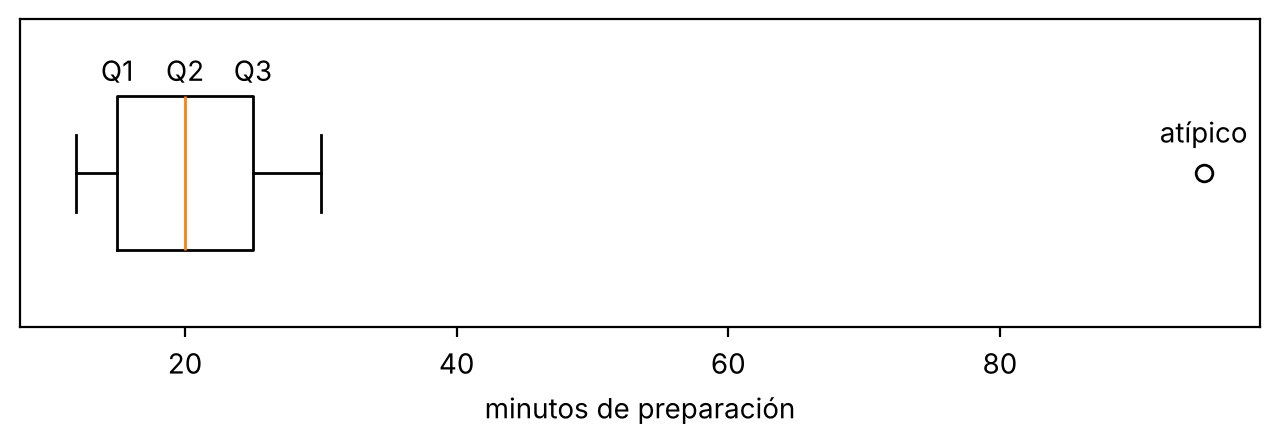

In [21]:
fig, ax = plt.subplots(figsize=(8, 2))
ax.boxplot(prep, orientation="horizontal", widths=0.5)
ax.set_xlabel("minutos de preparación"); ax.set_yticks([])
for x, txt in [(q1, "Q1"), (q2, "Q2"), (q3, "Q3")]:
    ax.annotate(txt, (x, 1.3), ha="center")
ax.annotate("atípico", (95, 1.1), ha="center")
plt.show()

> **Qué observar.** La caja va de Q1 a Q3 (el 50 % central), la raya es la mediana, los «bigotes» llegan hasta el último dato
dentro de los límites y lo que queda fuera se dibuja como punto: el pedido de 95 min.

> **Pregunta para la clase.** ¿Borramos el pedido de 95 minutos? ¿Qué necesitaríamos saber antes?

> Detectar un atípico **no significa borrarlo**: primero, ¿es un error o un dato real? Y la regla del IQR
> falla con datos muy asimétricos. Lo vemos con el millón de importes del apartado 1:

In [22]:
q1_i, q3_i = importes.quantile([0.25, 0.75])
lim_sup_i = q3_i + 1.5 * (q3_i - q1_i)
marcados = (importes > lim_sup_i).mean()
print(f"La regla del IQR marca como 'atípicos' el {marcados:.1%} de los importes")

La regla del IQR marca como 'atípicos' el 7.8% de los importes


> **Qué observar.** Ningún importe de esos es un error: es la **cola larga** normal de una distribución de importes.
Usa la regla como pista, no como veredicto.

### 3.7 Forma de la distribución

El **histograma** muestra cómo se reparten los datos. Con datos de negocio (importes, tiempos, sueldos)
lo habitual es la **asimetría a la derecha**: media > mediana.

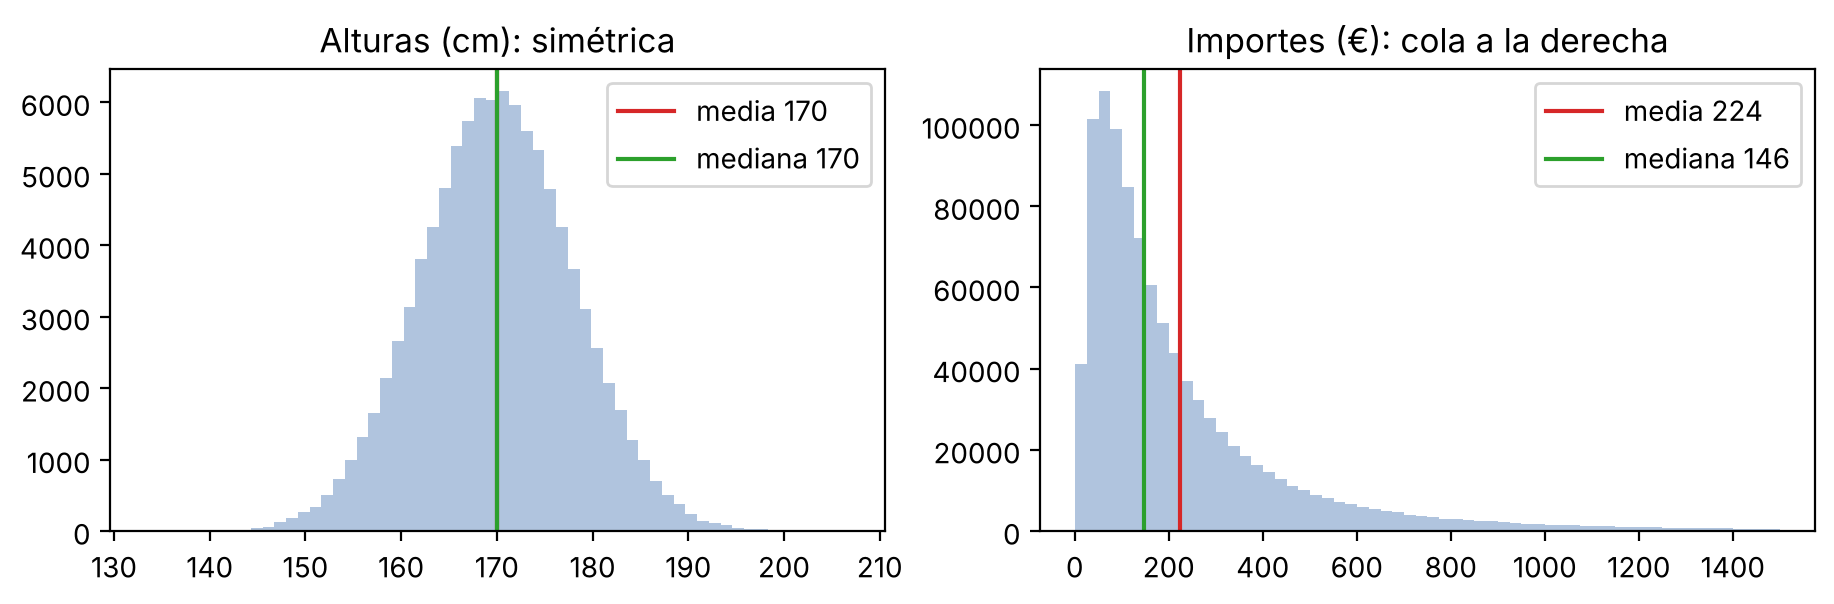

In [23]:
alturas = pd.Series(rng.normal(170, 8, 100_000))    # simétrica

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, datos, titulo in [(axes[0], alturas, "Alturas (cm): simétrica"),
                          (axes[1], importes[importes < 1500], "Importes (€): cola a la derecha")]:
    ax.hist(datos, bins=60, color="lightsteelblue")
    ax.axvline(datos.mean(), color="tab:red", label=f"media {datos.mean():.0f}")
    ax.axvline(datos.median(), color="tab:green", label=f"mediana {datos.median():.0f}")
    ax.set_title(titulo); ax.legend()
plt.show()

## 4. Funciones de agregación · 15 min

Vamos a hacer **cada consulta dos veces**: en SQL y en pandas. Para tener SQL sin instalar nada
usamos **SQLite** en memoria (viene con Python).

### 4.1 Funciones básicas y nulos

In [24]:
df = pd.DataFrame({
    "pedido_id":   [1, 2, 3, 4, 5],
    "importe":     [100, None, 50, None, 150],
    "metodo_pago": ["Tarjeta", "Bizum", "Tarjeta", None, "Tarjeta"],
})

con = sqlite3.connect(":memory:")
df.to_sql("pedidos", con, index=False)

def sql(consulta):
    return pd.read_sql(consulta, con)

df

,pedido_id,importe,metodo_pago
0,1,100.0,Tarjeta
1,2,NaN,Bizum
2,3,50.0,Tarjeta
3,4,NaN,NaN
4,5,150.0,Tarjeta


> **Pregunta para la clase.** Hay 5 pedidos y 2 no tienen importe. ¿Cuál es el importe medio: 100 o 60?

In [25]:
sql("""
SELECT COUNT(*)                     AS filas,
       COUNT(importe)               AS importes_conocidos,
       SUM(importe)                 AS suma,
       AVG(importe)                 AS media,
       SUM(importe) * 1.0 / COUNT(*) AS suma_entre_filas,
       COUNT(metodo_pago)           AS con_metodo,
       COUNT(DISTINCT metodo_pago)  AS metodos_distintos
FROM pedidos
""")

,filas,importes_conocidos,suma,media,suma_entre_filas,con_metodo,metodos_distintos
0,5,3,300.0,100.0,60.0,4,2


In [26]:
pd.Series({
    "filas (len)":              len(df),
    "importes_conocidos":       df["importe"].count(),
    "suma":                     df["importe"].sum(),
    "media":                    df["importe"].mean(),
    "suma_entre_filas":         df["importe"].sum() / len(df),
    "con_metodo":               df["metodo_pago"].count(),
    "metodos_distintos":        df["metodo_pago"].nunique(),
})

filas (len)             5.0
importes_conocidos      3.0
suma                  300.0
media                 100.0
suma_entre_filas       60.0
con_metodo              4.0
metodos_distintos       2.0
dtype: float64

In [27]:
df.isna().sum()

pedido_id      0
importe        2
metodo_pago    1
dtype: int64

> **Qué observar.** SQL y pandas dan exactamente lo mismo. Las agregaciones **ignoran los nulos** (salvo `COUNT(*)`):
100 es la media de los importes **conocidos**; 60 solo sería correcto si un nulo significara «0 €».
Ninguna es «la buena» en general: depende de qué significa el nulo. **Mira siempre los nulos antes de agregar.**

### 4.2 Agrupar: `GROUP BY` y 4.3 filtrar grupos: `HAVING`

Necesitamos una tabla un poco más grande. Generamos 1000 pedidos de 4 tiendas:

In [28]:
n = 1000
tiendas = rng.choice(["Vigo", "Coruña", "Santiago", "Lugo"], size=n, p=[0.4, 0.3, 0.2, 0.1])
categoria = rng.choice(["Hogar", "Deporte", "Electrónica"], size=n)
importe = rng.lognormal(4, 0.8, size=n) * np.where(categoria == "Electrónica", 3, 1)
pedidos = pd.DataFrame({"pedido_id": range(1, n + 1), "tienda": tiendas,
                        "categoria": categoria, "importe": importe.round(2)})
pedidos.to_sql("pedidos_grandes", con, index=False)
pedidos.head()

,pedido_id,tienda,categoria,importe
0,1,Coruña,Electrónica,233.57
1,2,Vigo,Hogar,55.93
2,3,Santiago,Deporte,104.61
3,4,Coruña,Hogar,77.68
4,5,Santiago,Deporte,176.01


In [29]:
sql("""
SELECT tienda,
       COUNT(*)     AS pedidos,
       SUM(importe) AS facturacion,
       AVG(importe) AS ticket_medio
FROM pedidos_grandes
GROUP BY tienda
ORDER BY facturacion DESC
""")

,tienda,pedidos,facturacion,ticket_medio
0,Vigo,373,54894.63,147.17
1,Coruña,318,39928.05,125.56
2,Santiago,208,23418.26,112.59
3,Lugo,101,10276.80,101.75


In [30]:
(pedidos.groupby("tienda")
        .agg(pedidos=("pedido_id", "count"),
             facturacion=("importe", "sum"),
             ticket_medio=("importe", "mean"))
        .sort_values("facturacion", ascending=False))

,pedidos,facturacion,ticket_medio
tienda,,,
Vigo,373,54894.63,147.17
Coruña,318,39928.05,125.56
Santiago,208,23418.26,112.59
Lugo,101,10276.80,101.75


`WHERE` filtra **filas antes** de agrupar; `HAVING` filtra **grupos después**. Orden lógico de SQL:
`FROM → WHERE → GROUP BY → HAVING → SELECT → ORDER BY`.

In [31]:
sql("""
SELECT categoria, AVG(importe) AS ticket_medio
FROM pedidos_grandes
GROUP BY categoria
HAVING AVG(importe) > 100
""")

,categoria,ticket_medio
0,Electrónica,229.52


In [32]:
res = pedidos.groupby("categoria").agg(ticket_medio=("importe", "mean"))
res[res["ticket_medio"] > 100]          # en pandas, el HAVING es un filtro normal después de agregar

,ticket_medio
categoria,
Electrónica,229.52


## 5. Agregados en sistemas distribuidos · 30 min

**El concepto central de la unidad.** En Spark o Hadoop los datos están **repartidos en particiones**
entre varios **nodos**. Cada nodo calcula un **resultado parcial** y después se **combinan**.

> **¿Se puede obtener el resultado global combinando solo los parciales?**

### 5.1 Ejemplo de partida

In [33]:
nodos = {
    "A": pd.Series([2, 4, 6]),
    "B": pd.Series([10, 20, 30, 40, 50]),
}
global_ = pd.concat(nodos.values(), ignore_index=True)
print("Global:", global_.tolist())

Global: [2, 4, 6, 10, 20, 30, 40, 50]


### 5.2 Distributivas: se combinan directamente

In [34]:
parciales = pd.DataFrame({nombre: {"sum": s.sum(), "count": s.count(), "max": s.max(), "min": s.min()}
                          for nombre, s in nodos.items()}).T
parciales

,sum,count,max,min
A,12,3,6,2
B,150,5,50,10


In [35]:
combinado = pd.Series({
    "sum":   parciales["sum"].sum(),
    "count": parciales["count"].sum(),
    "max":   parciales["max"].max(),
    "min":   parciales["min"].min(),
})
real = global_.agg(["sum", "count", "max", "min"])
pd.DataFrame({"combinando parciales": combinado, "sobre todos los datos": real})

,combinando parciales,sobre todos los datos
sum,162,162
count,8,8
max,50,50
min,2,2


> **Qué observar.** Coinciden. Cada nodo envía **un solo número**, tenga 3 datos o 3000 millones.

### 5.3 Algebraicas: la media

> **Pregunta para la clase.** Si cada nodo nos manda su media, ¿cuál es la media global?

In [36]:
medias = {n: s.mean() for n, s in nodos.items()}
print("Medias por nodo:", medias)
print("Media de las medias:", np.mean(list(medias.values())), "  ✘")
print("Media real:         ", global_.mean())

Medias por nodo: {'A': np.float64(4.0), 'B': np.float64(30.0)}
Media de las medias: 17.0   ✘
Media real:          20.25


In [37]:
# Lo correcto: cada nodo envía (suma, conteo)
suma_total = sum(s.sum() for s in nodos.values())
conteo_total = sum(s.count() for s in nodos.values())
print(f"({suma_total}) / ({conteo_total}) = {suma_total / conteo_total}  ✔")

(162) / (8) = 20.25  ✔


> **Qué observar.** El nodo B tiene más datos y debe pesar más: la media de medias es una **media no ponderada**
(apartado 2.5). Enviando dos números fijos, suma y conteo, se recupera la media exacta.

La **varianza** (y la desviación típica) también es **algebraica**: basta con que cada nodo envíe
**(suma, conteo, suma de cuadrados)**, tres agregados distributivos con los que se reconstruye la varianza
global. Promediar las varianzas de cada nodo, en cambio, da un resultado incorrecto.

### 5.4 Holísticas: la mediana

In [38]:
medianas = {n: s.median() for n, s in nodos.items()}
print("Medianas por nodo:", medianas)
print("Mediana de medianas:", np.mean(list(medianas.values())), "  ✘")
print("Mediana real:       ", global_.median())

Medianas por nodo: {'A': np.float64(4.0), 'B': np.float64(30.0)}
Mediana de medianas: 17.0   ✘
Mediana real:        15.0


> **Pregunta para la clase.** ¿Qué tendría que mandar cada nodo para poder calcular la mediana exacta?

> **Qué observar.** No hay un número fijo de valores que lo permita: hay que **reunir (u ordenar) todos los datos**.
Lo mismo pasa con la moda, los percentiles exactos y `COUNT DISTINCT`.

### Simulación a escala: 1 millón de importes en 4 nodos de tamaño distinto

Repartimos el millón de importes del apartado 1 entre 4 nodos (como haría Spark con las particiones)
y comparamos cada estrategia con el resultado real.

In [39]:
tamanos = [500_000, 300_000, 150_000, 50_000]
# Los nodos pequeños guardan datos de clientes "grandes" para que las particiones no sean iguales
ordenados_imp = importes.sort_values().to_numpy()
cortes = np.cumsum([0] + tamanos)
particiones = [pd.Series(ordenados_imp[cortes[i]:cortes[i + 1]]) for i in range(4)]

for i, p in enumerate(particiones):
    print(f"Nodo {i}: {len(p):>7,} filas  media {p.mean():8.2f}  mediana {p.median():8.2f}")

Nodo 0: 500,000 filas  media    77.66  mediana    75.76
Nodo 1: 300,000 filas  media   227.13  mediana   218.18
Nodo 2: 150,000 filas  media   494.84  mediana   468.20
Nodo 3:  50,000 filas  media  1273.96  mediana  1054.89


In [40]:
media_de_medias = np.mean([p.mean() for p in particiones])
media_suma_conteo = sum(p.sum() for p in particiones) / sum(p.count() for p in particiones)
mediana_de_medianas = np.median([p.median() for p in particiones])

pd.DataFrame({
    "estrategia": ["media de medias", "suma / conteo", "real",
                   "mediana de medianas", "real"],
    "medida": ["media", "media", "media", "mediana", "mediana"],
    "valor": [media_de_medias, media_suma_conteo, importes.mean(),
              mediana_de_medianas, importes.median()],
}).round(2)

,estrategia,medida,valor
0,media de medias,media,518.40
1,suma / conteo,media,244.89
2,real,media,244.89
3,mediana de medianas,mediana,343.19
4,real,mediana,148.30


> **Qué observar.** Con particiones desiguales, la media de medias y la mediana de medianas dan valores **muy alejados**
del real. Suma/conteo es exacto. Aquí lo hemos forzado ordenando los datos, pero en la realidad pasa
igual cuando cada nodo guarda una región, un día o un tipo de cliente distinto.

### 5.5 Resumen y consecuencias

| Tipo | Qué envía cada nodo | Coste de red | Ejemplos |
|---|---|---|---|
| Distributiva | 1 valor | Mínimo | SUM, COUNT, MIN, MAX |
| Algebraica | Unos pocos valores fijos | Mínimo | AVG, VAR, STDDEV |
| Holística | Todos los datos (o casi) | Muy alto | Mediana, moda, percentiles, COUNT DISTINCT |

- Sumas y conteos se **precombinan** en cada nodo (*combiners* en MapReduce/Spark).
- La mediana exacta de miles de millones de filas es **lenta y cara**.
- **Regla de diseño:** en tablas preagregadas guarda **sumas y conteos**, nunca medias.

## 6. Pincelada: agregados aproximados · 2–3 min

Si las holísticas son tan caras, muchas veces se acepta un resultado **aproximado**, con un error
pequeño y conocido, a cambio de muchísima menos memoria y tiempo. La forma más sencilla: **muestreo**.

| Problema | Técnica aproximada |
|---|---|
| Contar distintos | HyperLogLog (`approx_count_distinct` en Spark) |
| Percentiles y mediana | Resúmenes de cuantiles: Greenwald-Khanna, t-digest (`percentile_approx`) |
| Elementos más frecuentes | Count-Min Sketch |
| Casi cualquier agregado | Muestreo |

**Idea para quedarse:** en Big Data se negocia siempre entre **precisión, memoria y tiempo**.

## 7. Pincelada: agregación en el tiempo · 2–3 min

Los datos en *streaming* nunca dejan de llegar: se agregan por **ventanas temporales**.

| Ventana | Funcionamiento |
|---|---|
| Fija (*tumbling*) | Intervalos consecutivos sin solaparse |
| Deslizante (*sliding*) | Intervalos que se solapan y avanzan un paso |
| De sesión | Se cierra tras un tiempo de inactividad |

Ejemplo de cada una: **ventas de cada hora** (fija), **media de los últimos 7 días recalculada cada día**
(deslizante, la «media móvil») y **actividad de un usuario hasta que pasa 30 min sin hacer nada** (sesión).

## Cierre · 10–15 min

### Resumen

- **Media, mediana y moda** describen el valor típico. La media es sensible a extremos; la mediana es
  robusta; la moda sirve también para categorías.
- La **dispersión** se mide con rango, varianza, desviación típica, CV, cuartiles e IQR. Los
  **percentiles** (p95, p99) son clave en monitorización.
- Las **funciones de agregación** se combinan con `GROUP BY` y `HAVING`, en SQL igual que en pandas.
- En sistemas distribuidos las agregaciones son **distributivas**, **algebraicas** u **holísticas**, y
  eso determina su coste.
- Si el coste es demasiado alto, **agregados aproximados**; si los datos no paran de llegar,
  **ventanas temporales**.

### Dos preguntas para cerrar (en voz alta)

Después, el alumnado sigue con el **boletín de ejercicios** (`practicas/estadistica/ejercicios_estadistica.md` o su notebook).

**Pregunta 1.** Tres servidores informan de su tiempo medio de respuesta del día: 200 ms (10 000 peticiones),
250 ms (2000 peticiones) y 900 ms (50 peticiones). Un compañero dice que la media global es
(200 + 250 + 900) / 3 = 450 ms. ¿Es correcto? Calcula el valor real.

In [41]:
medias_srv = pd.DataFrame({"media_ms": [200, 250, 900], "peticiones": [10_000, 2_000, 50]})
print(f"Media de medias: {medias_srv['media_ms'].mean():.1f} ms  ✘")
print(f"Media real:      {np.average(medias_srv['media_ms'], weights=medias_srv['peticiones']):.1f} ms  ✔  (suma / conteo)")

Media de medias: 450.0 ms  ✘
Media real:      211.2 ms  ✔  (suma / conteo)


**Pregunta 2.** Clasifica como distributiva, algebraica u holística: `SUM`, `AVG`, mediana, `MAX`,
`COUNT DISTINCT`, desviación típica, moda, percentil 95.

In [42]:
pd.Series({
    "SUM": "distributiva", "MAX": "distributiva",
    "AVG": "algebraica (suma, conteo)", "desviación típica": "algebraica (suma, conteo, suma de cuadrados)",
    "mediana": "holística", "moda": "holística", "percentil 95": "holística", "COUNT DISTINCT": "holística",
}, name="tipo").to_frame()

,tipo
SUM,distributiva
MAX,distributiva
AVG,"algebraica (suma, conteo)"
desviación típica,"algebraica (suma, conteo, suma de cuadrados)"
mediana,holística
moda,holística
percentil 95,holística
COUNT DISTINCT,holística


---

# Para ampliar

Material extra para quien quiera profundizar. **No está en el manual de la web** (que es la versión
reducida); entre paréntesis se indica el apartado del manual con el que se relaciona. Las celdas usan variables del cuaderno, así que **ejecuta antes todo lo anterior**
(*Run → Run All Cells*).

## A. Mediana con n par (apartado 2.2)

Quitamos los 25 000 €:

In [43]:
sin_extremo = sueldos[sueldos < 25000]
print(sin_extremo.tolist())
print("Mediana:", sin_extremo.median(), "-> media de los dos centrales (1600 + 1800) / 2")
print("Media:  ", round(sin_extremo.mean(), 2))

[1500, 1600, 1600, 1800, 2000, 2200]
Mediana: 1700.0 -> media de los dos centrales (1600 + 1800) / 2
Media:   1783.33


> **Qué observar.** La mediana (1700 €) **no aparece en los datos**. Y sin el extremo, media y mediana vuelven a estar cerca.

## B. Rango (apartado 3.1)

In [44]:
print("Rango con todos los sueldos:", sueldos.max() - sueldos.min())
print("Rango sin el de 25 000 €:   ", sin_extremo.max() - sin_extremo.min())

Rango con todos los sueldos: 23500
Rango sin el de 25 000 €:    700


> **Qué observar.** Un solo valor multiplica el rango por más de 30: depende solo de dos datos, los extremos.

## C. pandas frente a NumPy: `ddof` (apartado 3.2)

In [45]:
print("pandas  (ddof=1, divide entre n-1):", A.var(), A.std())
print("NumPy   (ddof=0, divide entre n):  ", round(np.var(A), 2), round(np.std(A), 2))
print("pandas forzando ddof=0:            ", round(A.std(ddof=0), 2))

pandas  (ddof=1, divide entre n-1): 4.0 2.0
NumPy   (ddof=0, divide entre n):   2.67 1.63
pandas forzando ddof=0:             1.63


> **Qué observar.** **pandas y NumPy no dan lo mismo**: con 3 datos se nota; con millones de filas, la diferencia es despreciable.

## D. Coeficiente de variación (apartado 3.3)

$CV = \dfrac{s}{\bar{x}} \cdot 100\%$: compara la dispersión de variables con escalas distintas.

In [46]:
categorias = pd.DataFrame({"media": [20, 800], "desv_tipica": [4, 80]}, index=["Libros", "Ordenadores"])
categorias["CV_%"] = categorias["desv_tipica"] / categorias["media"] * 100
categorias

,media,desv_tipica,CV_%
Libros,20,4,20.0
Ordenadores,800,80,10.0


> **Pregunta para la clase.** Mirando solo la desviación típica, ¿qué categoría tiene precios más dispersos? ¿Y mirando el CV?

> **Qué observar.** En euros, los ordenadores varían 20 veces más; **en relación con su precio**, son más homogéneos que los libros.

## E. Coeficiente de asimetría (apartado 3.7)

In [47]:
pd.DataFrame({
    "media": [A.mean(), sueldos.mean(), alturas.mean(), importes.mean()],
    "mediana": [A.median(), sueldos.median(), alturas.median(), importes.median()],
    "skew": [A.skew(), sueldos.skew(), alturas.skew(), importes.skew()],
}, index=["A", "sueldos", "alturas", "importes"]).round(2)

,media,mediana,skew
A,50.00,50.00,0.00
sueldos,5100.00,1800.00,2.64
alturas,170.02,170.01,0.01
importes,244.89,148.30,6.76


> **Qué observar.** El **coeficiente de asimetría** resume la forma: ≈ 0 simétrica; positivo, cola a la derecha;
negativo, cola a la izquierda. Los sueldos dan 2,64, como en el manual.

## F. ¿Por qué no se puede usar un agregado en `WHERE`? (apartado 4.3)

In [48]:
# ¿Por qué no se puede poner el agregado en WHERE? Porque aún no existe:
try:
    sql("SELECT categoria FROM pedidos_grandes WHERE AVG(importe) > 100 GROUP BY categoria")
except Exception as e:
    print(type(e).__name__, "->", str(e).split("': ")[-1])

DatabaseError -> misuse of aggregate: AVG()


## G. Varianza combinada a partir de (suma, conteo, suma de cuadrados) (apartado 5.3)

$$s^2 = \frac{\sum x_i^2 - \dfrac{(\sum x_i)^2}{n}}{n - 1}$$

In [49]:
tabla = pd.DataFrame({n: {"suma": s.sum(), "conteo": s.count(), "suma_cuadrados": (s ** 2).sum(),
                          "varianza_local": s.var()}
                      for n, s in nodos.items()}).T
tabla.loc["Global (se suman)"] = tabla[["suma", "conteo", "suma_cuadrados"]].sum()
tabla

,suma,conteo,suma_cuadrados,varianza_local
A,12.0,3.0,56.0,4.0
B,150.0,5.0,5500.0,250.0
Global (se suman),162.0,8.0,5556.0,NaN


In [50]:
S, N, S2 = tabla.loc["Global (se suman)", ["suma", "conteo", "suma_cuadrados"]]
var_combinada = (S2 - S ** 2 / N) / (N - 1)

print(f"Varianza combinando parciales: {var_combinada:.2f}")
print(f"Varianza real:                 {global_.var():.2f}")
print(f"Media de varianzas locales:    {tabla['varianza_local'].iloc[:2].mean():.2f}  ✘")

Varianza combinando parciales: 325.07
Varianza real:                 325.07
Media de varianzas locales:    127.00  ✘


## H. Agregados aproximados con muestreo (apartado 6)

In [51]:
muestra = importes.sample(frac=0.01, random_state=1)     # 10 000 filas de 1 000 000

comp = pd.DataFrame({
    "exacto (1 000 000)": [importes.median(), importes.quantile(0.99)],
    "muestra (10 000)":   [muestra.median(),  muestra.quantile(0.99)],
}, index=["mediana", "p99"])
comp["error_%"] = (comp.iloc[:, 1] / comp.iloc[:, 0] - 1).abs() * 100
comp.round(2)

,exacto (1 000 000),muestra (10 000),error_%
mediana,148.30,146.98,0.89
p99,1522.27,1448.58,4.84


In [52]:
%timeit importes.median()
%timeit muestra.median()

17.6 ms ± 1.27 ms per loop (mean ± std. dev. of 7 runs, 100 loops each)


215 μs ± 14.2 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


> **Qué observar.** La mediana aproximada se desvía menos de un 1 % procesando 100 veces menos datos. El **p99 se
desvía más**: en la cola hay pocos datos y una muestra pequeña los captura peor. En Big Data se negocia
siempre entre **precisión, memoria y tiempo**.

En Spark existen funciones aproximadas basadas en algoritmos como HyperLogLog o t-digest
(no hace falta ejecutarlo hoy):

```python
from pyspark.sql import functions as F
df.agg(F.countDistinct("cliente_id"),                       # exacto: holístico, caro
       F.approx_count_distinct("cliente_id", rsd=0.01))     # aproximado: error máximo 1 %
df.agg(F.percentile_approx("tiempo_ms", [0.5, 0.95, 0.99]))
```

| Problema | Técnica aproximada |
|---|---|
| Contar distintos | HyperLogLog |
| Percentiles y mediana | Resúmenes de cuantiles (Greenwald-Khanna, t-digest) |
| Elementos más frecuentes | Count-Min Sketch |
| Casi cualquier agregado | Muestreo |

## I. Ventanas temporales en pandas (apartado 7)

### Ventana fija y deslizante: ventas diarias y media móvil

Generamos tres meses de pedidos con un patrón semanal (los sábados se vende más):

In [53]:
horas = pd.date_range("2026-03-01", "2026-05-31 23:00", freq="h")
pedidos_t = pd.DataFrame({"fecha_hora": rng.choice(horas, size=20_000)})
pedidos_t["importe"] = rng.lognormal(4, 0.7, len(pedidos_t)) * np.where(
    pedidos_t["fecha_hora"].dt.dayofweek == 5, 1.8, 1)
pedidos_t.head()

,fecha_hora,importe
0,2026-04-29 20:00:00,92.06
1,2026-03-09 11:00:00,116.68
2,2026-05-04 00:00:00,89.05
3,2026-03-31 18:00:00,65.74
4,2026-03-17 02:00:00,22.28


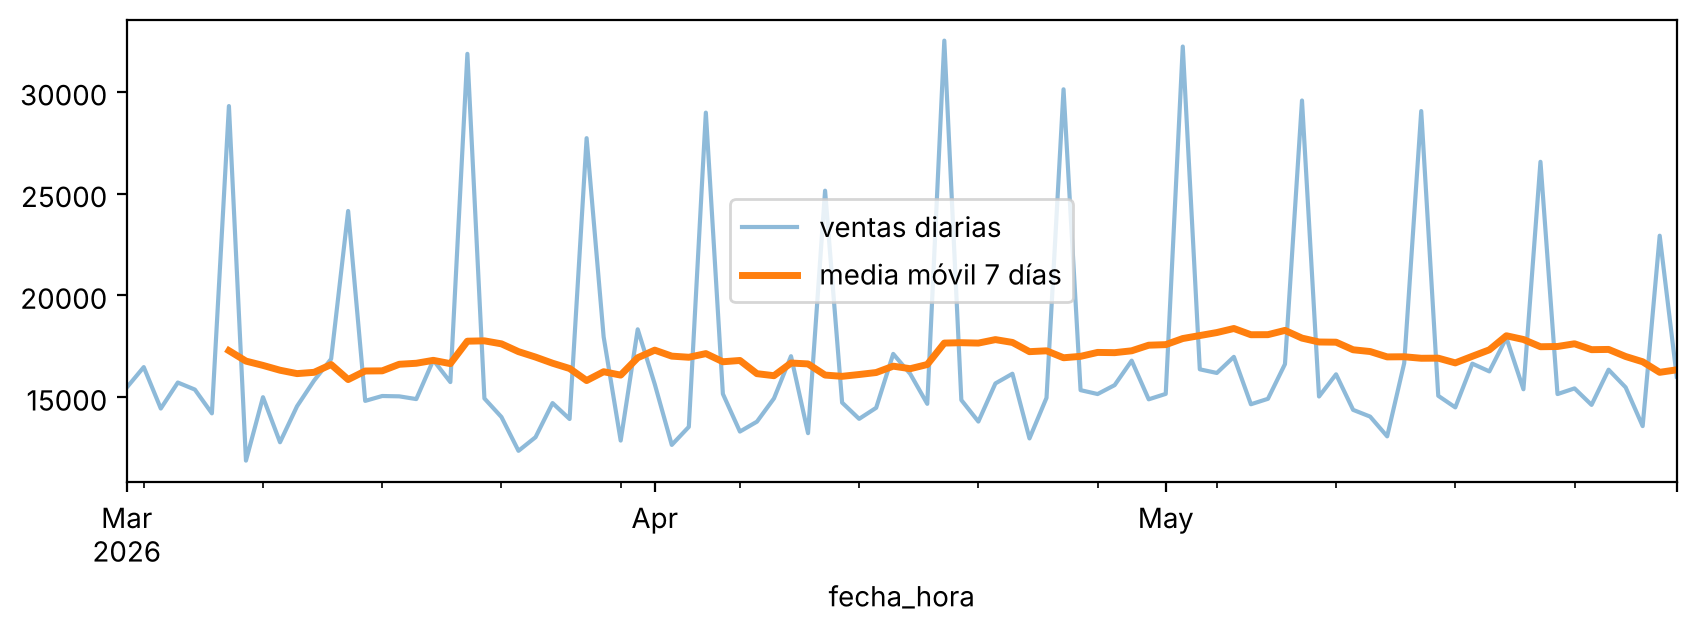

In [54]:
ventas_diarias = pedidos_t.set_index("fecha_hora").resample("D")["importe"].sum()   # ventana FIJA de 1 día
media_movil_7d = ventas_diarias.rolling(7).mean()                                 # ventana DESLIZANTE de 7 días

ax = ventas_diarias.plot(label="ventas diarias", alpha=0.5, figsize=(10, 3))
media_movil_7d.plot(ax=ax, label="media móvil 7 días", linewidth=2.5)
ax.legend(); plt.show()

> **Qué observar.** Los picos son los sábados. La media móvil los suaviza y deja ver la tendencia. Los 6 primeros días
no tienen media móvil: todavía no hay 7 días en la ventana.

In [55]:
pd.DataFrame({"ventas": ventas_diarias, "media_7d": media_movil_7d}).head(9)

,ventas,media_7d
fecha_hora,,
2026-03-01,15467.24,NaN
2026-03-02,16471.50,NaN
2026-03-03,14436.64,NaN
2026-03-04,15713.75,NaN
2026-03-05,15368.44,NaN
2026-03-06,14199.29,NaN
2026-03-07,29299.26,17279.45
2026-03-08,11877.16,16766.58
2026-03-09,14993.68,16555.46


### Ventana de sesión

Clics de un usuario con un umbral de inactividad de 30 minutos. **La duración de cada sesión no se
conoce de antemano**: depende de los datos.

In [56]:
clics = pd.DataFrame({
    "usuario": ["u1"] * 6,
    "hora": pd.to_datetime(["2026-03-02 10:00", "2026-03-02 10:05", "2026-03-02 10:12",
                            "2026-03-02 10:50", "2026-03-02 10:55", "2026-03-02 12:00"]),
}).sort_values(["usuario", "hora"])

clics["hueco"] = clics.groupby("usuario")["hora"].diff()                    # tiempo desde el clic anterior
clics["nueva"] = clics["hueco"].isna() | (clics["hueco"] > pd.Timedelta("30min"))
clics["sesion"] = clics["nueva"].groupby(clics["usuario"]).cumsum()         # numerar sesiones
clics

,usuario,hora,hueco,nueva,sesion
0,u1,2026-03-02 10:00:00,NaT,True,1
1,u1,2026-03-02 10:05:00,0 days 00:05:00,False,1
2,u1,2026-03-02 10:12:00,0 days 00:07:00,False,1
3,u1,2026-03-02 10:50:00,0 days 00:38:00,True,2
4,u1,2026-03-02 10:55:00,0 days 00:05:00,False,2
5,u1,2026-03-02 12:00:00,0 days 01:05:00,True,3


> **Qué observar.** Paso a paso: `diff()` calcula el hueco con el clic anterior; si es mayor de 30 min (o es el primero),
empieza sesión; `cumsum()` sobre los `True` numera las sesiones (cada `True` suma 1).

In [57]:
clics.groupby(["usuario", "sesion"]).agg(inicio=("hora", "min"),
                                         fin=("hora", "max"),
                                         clics=("hora", "size"))

inicio                 fin  clics
usuario sesion                                               
u1      1      2026-03-02 10:00:00 2026-03-02 10:12:00      3
        2      2026-03-02 10:50:00 2026-03-02 10:55:00      2
        3      2026-03-02 12:00:00 2026-03-02 12:00:00      1

En Spark Structured Streaming existe directamente `F.session_window("hora", "30 minutes")`.

## J. Errores habituales (apartado 8)

| Error | Qué hacer |
|---|---|
| Usar la media con datos muy asimétricos | Comparar con la mediana e informar de ambas |
| Promediar medias de grupos de distinto tamaño | Combinar sumas y conteos |
| Calcular la mediana de medianas | Recalcular sobre los datos o usar un resumen de cuantiles |
| Confundir `COUNT(*)` con `COUNT(col)` | Elegir conscientemente cuál se necesita |
| Borrar *outliers* sin investigarlos | Verificar si son errores o casos reales |
| No eliminar duplicados antes de agregar | Revisar la calidad del dato antes de agregar |
| Informar de la media de tiempos de respuesta | Usar p95 / p99 |

Una demostración rápida del error de los **duplicados**:

In [58]:
con_duplicados = pd.concat([df, df.iloc[[0, 0]]], ignore_index=True)   # el pedido 1 llega 3 veces
print("Suma real:          ", df["importe"].sum())
print("Suma con duplicados:", con_duplicados["importe"].sum())
print("Tras drop_duplicates:", con_duplicados.drop_duplicates()["importe"].sum())

Suma real:           300.0
Suma con duplicados: 500.0
Tras drop_duplicates: 300.0


## K. Más preguntas de repaso

In [59]:
a1 = pd.Series([120, 135, 140, 150, 160, 170, 2400])
print(f"Tiempos de respuesta · media {a1.mean():.1f}  mediana {a1.median()}  rango {a1.max() - a1.min()}")

Tiempos de respuesta · media 467.9  mediana 150.0  rango 2280


In [60]:
# Tiendas con más de 200 pedidos: número de pedidos y ticket medio
sql("""
SELECT tienda, COUNT(*) AS pedidos, AVG(importe) AS ticket_medio
FROM pedidos_grandes
GROUP BY tienda
HAVING COUNT(*) > 200
""")

,tienda,pedidos,ticket_medio
0,Coruña,318,125.56
1,Santiago,208,112.59
2,Vigo,373,147.17
